Load Climate Models and Dataset

In [ ]:
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

# 1. Locate project root
project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "experiments" / "02_climate" / "02_climate_model.ipynb").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Climate project directory not found")

# 2. Local paths
experiment_dir = project_root / "experiments" / "02_climate"
model_notebook = experiment_dir / "02_climate_model.ipynb"
dataset_path = experiment_dir / "data" / "wind_nearest_5sites.pt"

results_dir = experiment_dir / "results" / "climate_grid_search_e4000"
metrics_path = results_dir / "metrics.csv"

# 3. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 4. Load model definitions
get_ipython().run_line_magic(
    "run", f'"{model_notebook.as_posix()}"'
)

# 5. Load dataset
dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=True
)

x_in = dataset["x_in"]
x_out = dataset["x_out"]

patch_len = dataset["patch_len"]
horizon = dataset["horizon"]
input_dim = x_in.shape[-1]
wind_raw = dataset["wind_raw"].cpu().numpy()

# 6. Grid Search configuration
patch_lengths = [80, 90, 100, 110, 120, 130]
horizons = [10, 15, 20, 25, 30]
d_model = 48
epochs = 4000

# 7. Verify local environment
print("\n=== CLIMATE EXPERIMENT - LOCAL ===")
print("Project:", project_root)
print("Device:", device)
print("Dataset:", dataset_path)
print("X:", x_in.shape)
print("Y:", x_out.shape)
print("Grid Search results:", results_dir)
print("Results directory exists:", results_dir.is_dir())
print("Metrics file exists:", metrics_path.is_file())

if metrics_path.is_file():
    metrics = pd.read_csv(metrics_path)
    print("Completed training runs:", len(metrics))


=== CLIMATE EXPERIMENT ===
Device: cuda
X: torch.Size([310, 80, 5])
Y: torch.Size([310, 50])
Input dimension: 5
Patch length: 80
Forecast horizon: 10

=== CLIMATE EXPERIMENT - LOCAL ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
Dataset: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\data\wind_nearest_5sites.pt
X: torch.Size([310, 80, 5])
Y: torch.Size([310, 50])
Grid Search results: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\climate_grid_search_e4000
Results directory exists: True
Metrics file exists: True
Completed training runs: 120


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Training Function

In [2]:


def train(model, x_in, x_out, epochs=4000, lr=3e-4, koop_attr="koop", lyap_weight=0.1):

    model.to(device)
    x_in, x_out = x_in.to(device), x_out.to(device)

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    mse = nn.MSELoss()
    losses, eigs = [], []

    # Lyapunov matrix
    with torch.no_grad():
        _, z, z_next = model(x_in[:1], return_latents=True)

    P = torch.eye(z.shape[1], device=device)

    for ep in range(epochs):
        model.train()
        opt.zero_grad()

        pred, z, z_next = model(x_in, return_latents=True)
        pred_loss = mse(pred, x_out)

        if lyap_weight:
            zp = torch.einsum("bi,ij->bj", z, P)
            znp = torch.einsum("bi,ij->bj", z_next, P)

            lyap = torch.relu(
                (znp * z_next).sum(1) -
                (zp * z).sum(1)
            ).mean()
        else:
            lyap = torch.zeros(1, device=device)

        loss = pred_loss + lyap_weight * lyap
        loss.backward()
        opt.step()

        losses.append(loss.item())

        obj = getattr(model, koop_attr, None) if koop_attr else None
        eig_raw = (
            obj.S_raw if isinstance(obj, StrictStableKoopmanOperator)
            else None
        )

        eigs.append(
            0.0 if eig_raw is None
            else torch.sigmoid(eig_raw).abs().max().item()
        )

        if ep % max(1, epochs // 10) == 0 or ep == epochs - 1:
            print(
                f"Epoch {ep:>4}/{epochs} "
                f"MSE {pred_loss.item():.5f} "
                f"Lyap {(lyap_weight * lyap).item():.5f}"
            )

    model.eval()
    with torch.no_grad():
        preds = model(x_in).cpu().numpy()

    return preds, np.array(losses), np.array(eigs)


Climate Experiment Configuration

In [3]:

patch_lengths = [80, 90, 100, 110, 120, 130]
horizons = [10, 15, 20, 25, 30]

d_model = 48
epochs = 4000
learning_rate = 3e-4

location_indices = [0, 5000, 10000, 15000, 20000]

wind_raw = dataset["wind_raw"].cpu().numpy()

results_dir = Path("/kaggle/working/climate_grid_search_e4000")
results_dir.mkdir(parents=True, exist_ok=True)

print("=== CLIMATE GRID SEARCH ===")
print("Patch lengths:", patch_lengths)
print("Horizons:", horizons)
print("d_model:", d_model)
print("Epochs:", epochs)
print("Total configurations:", len(patch_lengths) * len(horizons))
print("Total training runs:", len(patch_lengths) * len(horizons) * 4)


=== CLIMATE GRID SEARCH ===
Patch lengths: [80, 90, 100, 110, 120, 130]
Horizons: [10, 15, 20, 25, 30]
d_model: 48
Epochs: 4000
Total configurations: 30
Total training runs: 120


Full Climate Grid Search Training

In [4]:

import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from contextlib import redirect_stdout
from io import StringIO

# 1. Reproducibility
np.random.seed(7)
torch.manual_seed(7)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(7)

metrics_path = results_dir / "metrics.csv"
records = {}

# 2. Iterate over configurations
for p in patch_lengths:
    for h in horizons:

        print(f"\n=== Patch Length: {p} | Horizon: {h} ===")

        # Normalize and create sliding windows
        sub = MinMaxScaler().fit_transform(wind_raw[:400, :])

        X, Y = [], []
        for i in range(len(sub) - p - h):
            X.append(sub[i:i + p])
            Y.append(sub[i + p:i + p + h].T.reshape(-1))

        x_grid = torch.tensor(np.stack(X), dtype=torch.float32)
        y_grid = torch.tensor(np.stack(Y), dtype=torch.float32)

        F = x_grid.shape[-1]

        # 3. Create new models for this configuration
        model_factories = {
            "LSTM": lambda: SimpleLSTMForecaster(F, 64, 2, h),
            "PatchTST": lambda: Koopformer_PatchTST(
                F, p, h, patch_len=p, d_model=d_model
            ),
            "Autoformer": lambda: Koopformer_Autoformer(
                F, p, h, patch_len=p, d_model=d_model
            ),
            "Informer": lambda: Koopformer_Informer(
                F, p, h, patch_len=p, d_model=d_model
            )
        }

        for name, create_model in model_factories.items():
            checkpoint_path = results_dir / f"{name.lower()}_p{p}_h{h}.pt"
            key = (name, p, h)

            # Resume from existing checkpoint
            if checkpoint_path.exists():
                saved = torch.load(
                    checkpoint_path,
                    map_location="cpu",
                    weights_only=True
                )
                mse_value = float(saved["mse"])
                mae_value = float(saved["mae"])
                print(f"{name:<12} Loaded checkpoint")

            else:
                model = create_model()

                # 4. Train using original author's function
                with redirect_stdout(StringIO()):
                    preds, losses, eigs = train(
                        model,
                        x_grid,
                        y_grid,
                        epochs=epochs,
                        lr=learning_rate,
                        koop_attr=None if name == "LSTM" else "koop",
                        lyap_weight=0.0 if name == "LSTM" else 0.1
                    )

                truth = y_grid.numpy()
                mse_value = float(np.mean((preds - truth) ** 2))
                mae_value = float(np.mean(np.abs(preds - truth)))

                # 5. Save model, predictions and training history
                torch.save({
                    "model_state_dict": model.cpu().state_dict(),
                    "pred": torch.from_numpy(preds),
                    "truth": y_grid.cpu(),
                    "loss": torch.from_numpy(losses),
                    "eig": torch.from_numpy(eigs),
                    "mse": mse_value,
                    "mae": mae_value,
                    "patch_len": p,
                    "horizon": h,
                    "d_model": d_model,
                    "input_dim": F,
                    "epochs": epochs
                }, checkpoint_path)

                del model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

                print(f"{name:<12} Training completed")

            print(f"  MSE: {mse_value:.6f} | MAE: {mae_value:.6f}")

            records[key] = {
                "Model": name,
                "PatchLen": p,
                "Horizon": h,
                "d_model": d_model,
                "MSE": mse_value,
                "MAE": mae_value
            }

            # Save metrics after each completed run
            pd.DataFrame(records.values()).to_csv(
                metrics_path, index=False
            )

print("\n=== GRID SEARCH COMPLETED ===")
print("Completed runs:", len(records))
print("Metrics saved to:", metrics_path)



=== Patch Length: 80 | Horizon: 10 ===
LSTM         Training completed
  MSE: 0.006458 | MAE: 0.060318
PatchTST     Training completed
  MSE: 0.004726 | MAE: 0.051087
Autoformer   Training completed
  MSE: 0.007338 | MAE: 0.065195
Informer     Training completed
  MSE: 0.002175 | MAE: 0.034726

=== Patch Length: 80 | Horizon: 15 ===
LSTM         Training completed
  MSE: 0.009620 | MAE: 0.074312
PatchTST     Training completed
  MSE: 0.003970 | MAE: 0.045991
Autoformer   Training completed
  MSE: 0.007571 | MAE: 0.066193
Informer     Training completed
  MSE: 0.003458 | MAE: 0.043394

=== Patch Length: 80 | Horizon: 20 ===
LSTM         Training completed
  MSE: 0.006216 | MAE: 0.059218
PatchTST     Training completed
  MSE: 0.005264 | MAE: 0.054053
Autoformer   Training completed
  MSE: 0.006985 | MAE: 0.063441
Informer     Training completed
  MSE: 0.003867 | MAE: 0.045930

=== Patch Length: 80 | Horizon: 25 ===
LSTM         Training completed
  MSE: 0.007728 | MAE: 0.066866
PatchTST

Grid Search MSE/MAE Heatmaps

=== GRID SEARCH: 4000 EPOCHS ===
Total runs: 120
Metrics: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\climate_grid_search_e4000\metrics.csv


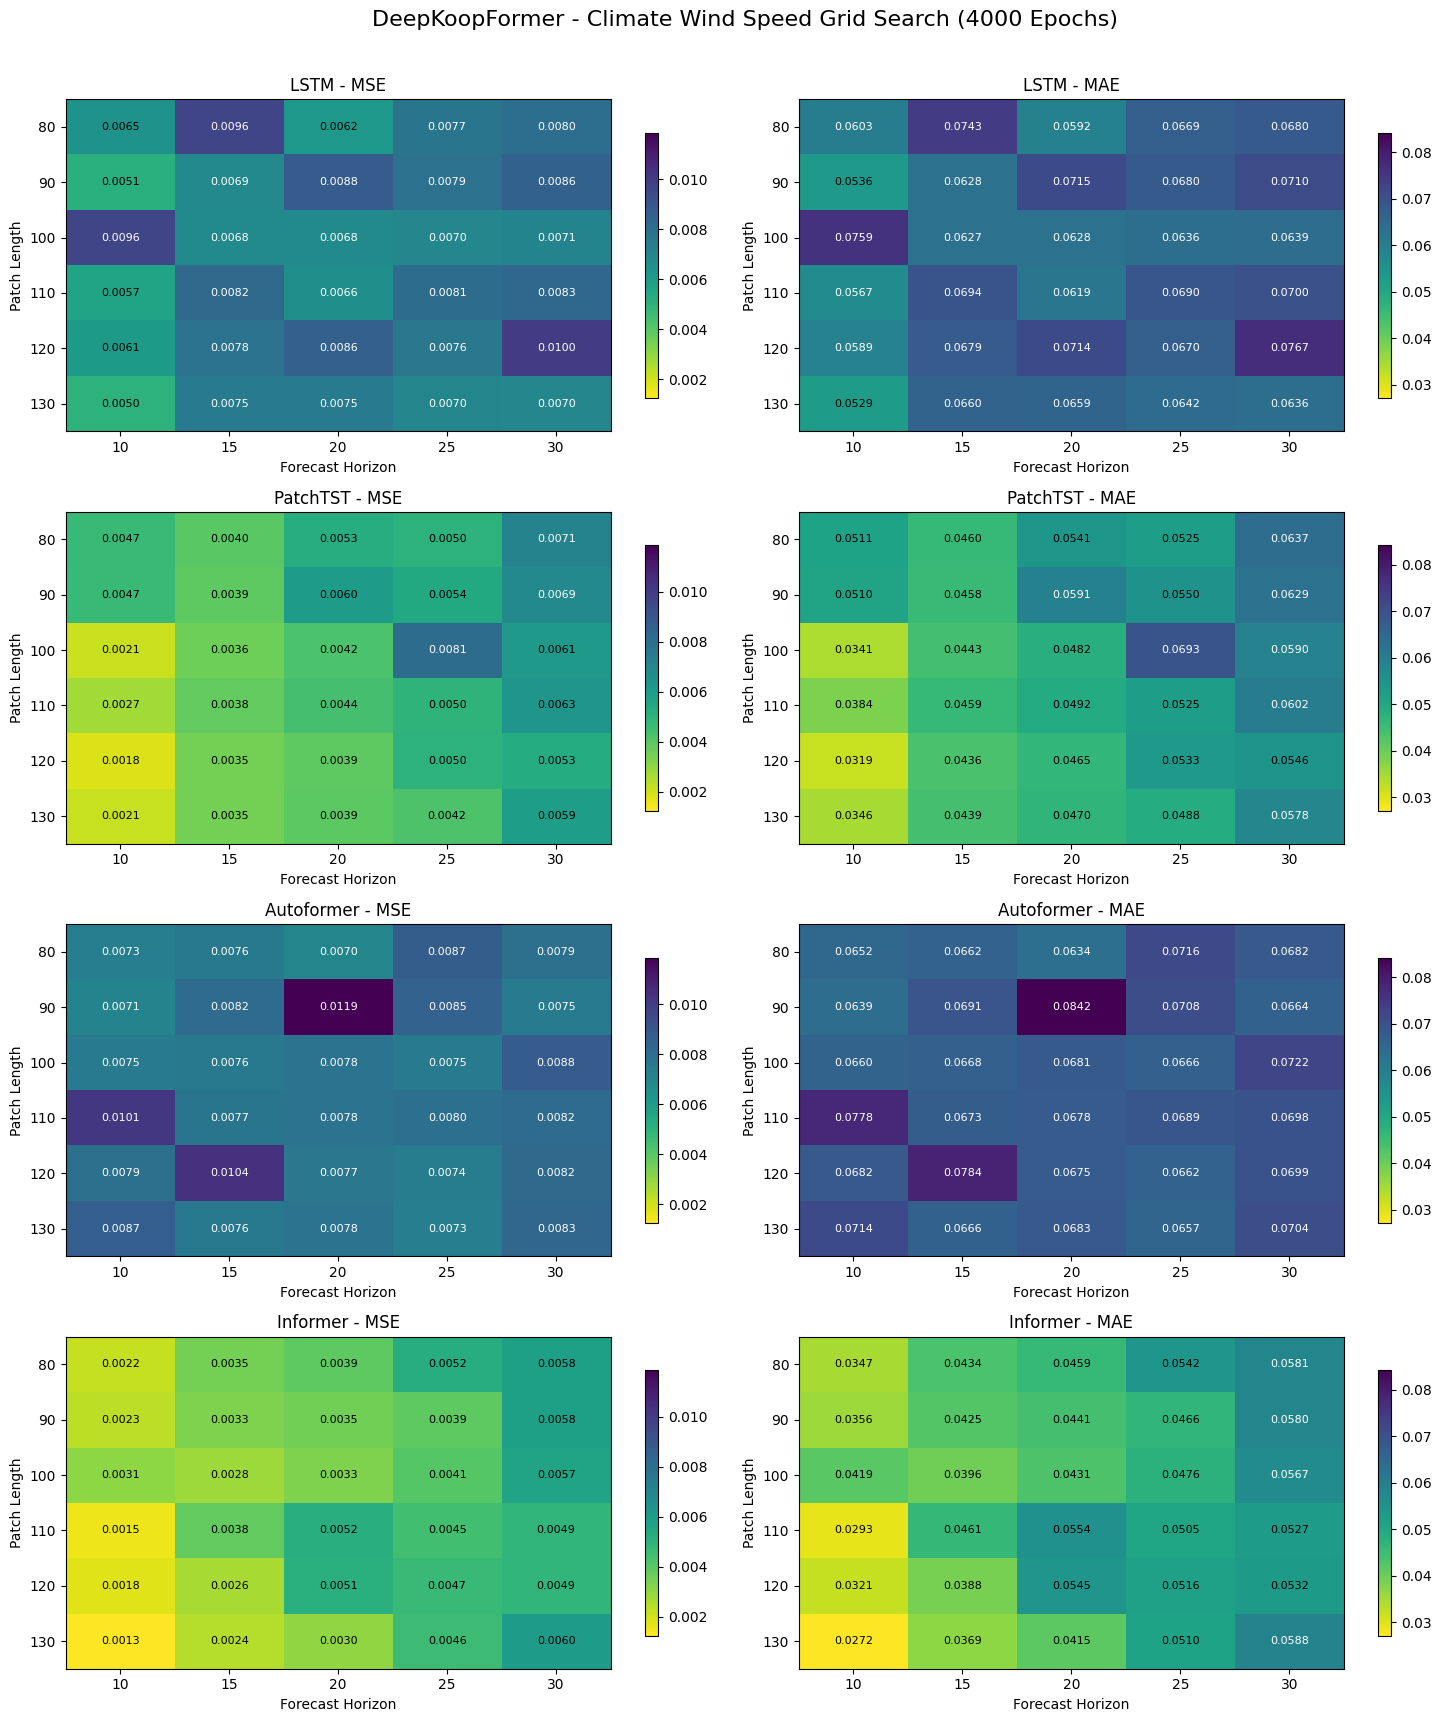

Figure saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\climate_grid_search_e4000\grid_search_mse_mae_heatmaps_e4000.png


In [3]:

# Cell 5 - Grid Search MSE/MAE Heatmaps (4000 Epochs)

import matplotlib.pyplot as plt
import pandas as pd

# 1. Load 4000-epoch results
results_dir = experiment_dir / "results" / "climate_grid_search_e4000"
metrics_path = results_dir / "metrics.csv"

if not metrics_path.exists():
    raise FileNotFoundError(f"Metrics not found: {metrics_path}")

metrics = pd.read_csv(metrics_path)

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
metric_names = ["MSE", "MAE"]

# 2. Verify all configurations
expected = {
    (m, p, h)
    for m in model_names
    for p in patch_lengths
    for h in horizons
}

actual = set(
    zip(metrics["Model"], metrics["PatchLen"], metrics["Horizon"])
)

assert expected == actual, f"Missing configurations: {expected - actual}"
assert len(metrics) == 120, f"Expected 120 runs, got {len(metrics)}"

print("=== GRID SEARCH: 4000 EPOCHS ===")
print("Total runs:", len(metrics))
print("Metrics:", metrics_path)

# 3. Shared color scales for fair model comparison
scales = {
    metric: (metrics[metric].min(), metrics[metric].max())
    for metric in metric_names
}

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

for row, model_name in enumerate(model_names):
    model_data = metrics[metrics["Model"] == model_name]

    for col, metric_name in enumerate(metric_names):
        ax = axes[row, col]

        heatmap_data = model_data.pivot(
            index="PatchLen",
            columns="Horizon",
            values=metric_name
        ).reindex(index=patch_lengths, columns=horizons)

        values = heatmap_data.to_numpy()
        vmin, vmax = scales[metric_name]

        im = ax.imshow(
            values,
            cmap="viridis_r",
            aspect="auto",
            vmin=vmin,
            vmax=vmax
        )

        for i in range(len(patch_lengths)):
            for j in range(len(horizons)):
                value = values[i, j]

                ax.text(
                    j, i, f"{value:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if im.norm(value) > 0.5 else "black"
                )

        ax.set_xticks(range(len(horizons)), horizons)
        ax.set_yticks(range(len(patch_lengths)), patch_lengths)

        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("Patch Length")
        ax.set_title(f"{model_name} - {metric_name}")
        fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(
    "DeepKoopFormer - Climate Wind Speed Grid Search (4000 Epochs)",
    fontsize=16, y=1.01
)

plt.tight_layout()

save_path = results_dir / "grid_search_mse_mae_heatmaps_e4000.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", save_path)


Reproduce Figure 4 (Patch 130, Horizon 20)

LSTM: MSE=0.007477, MAE=0.065927
PatchTST: MSE=0.003921, MAE=0.046967
Autoformer: MSE=0.007805, MAE=0.068256
Informer: MSE=0.003011, MAE=0.041517


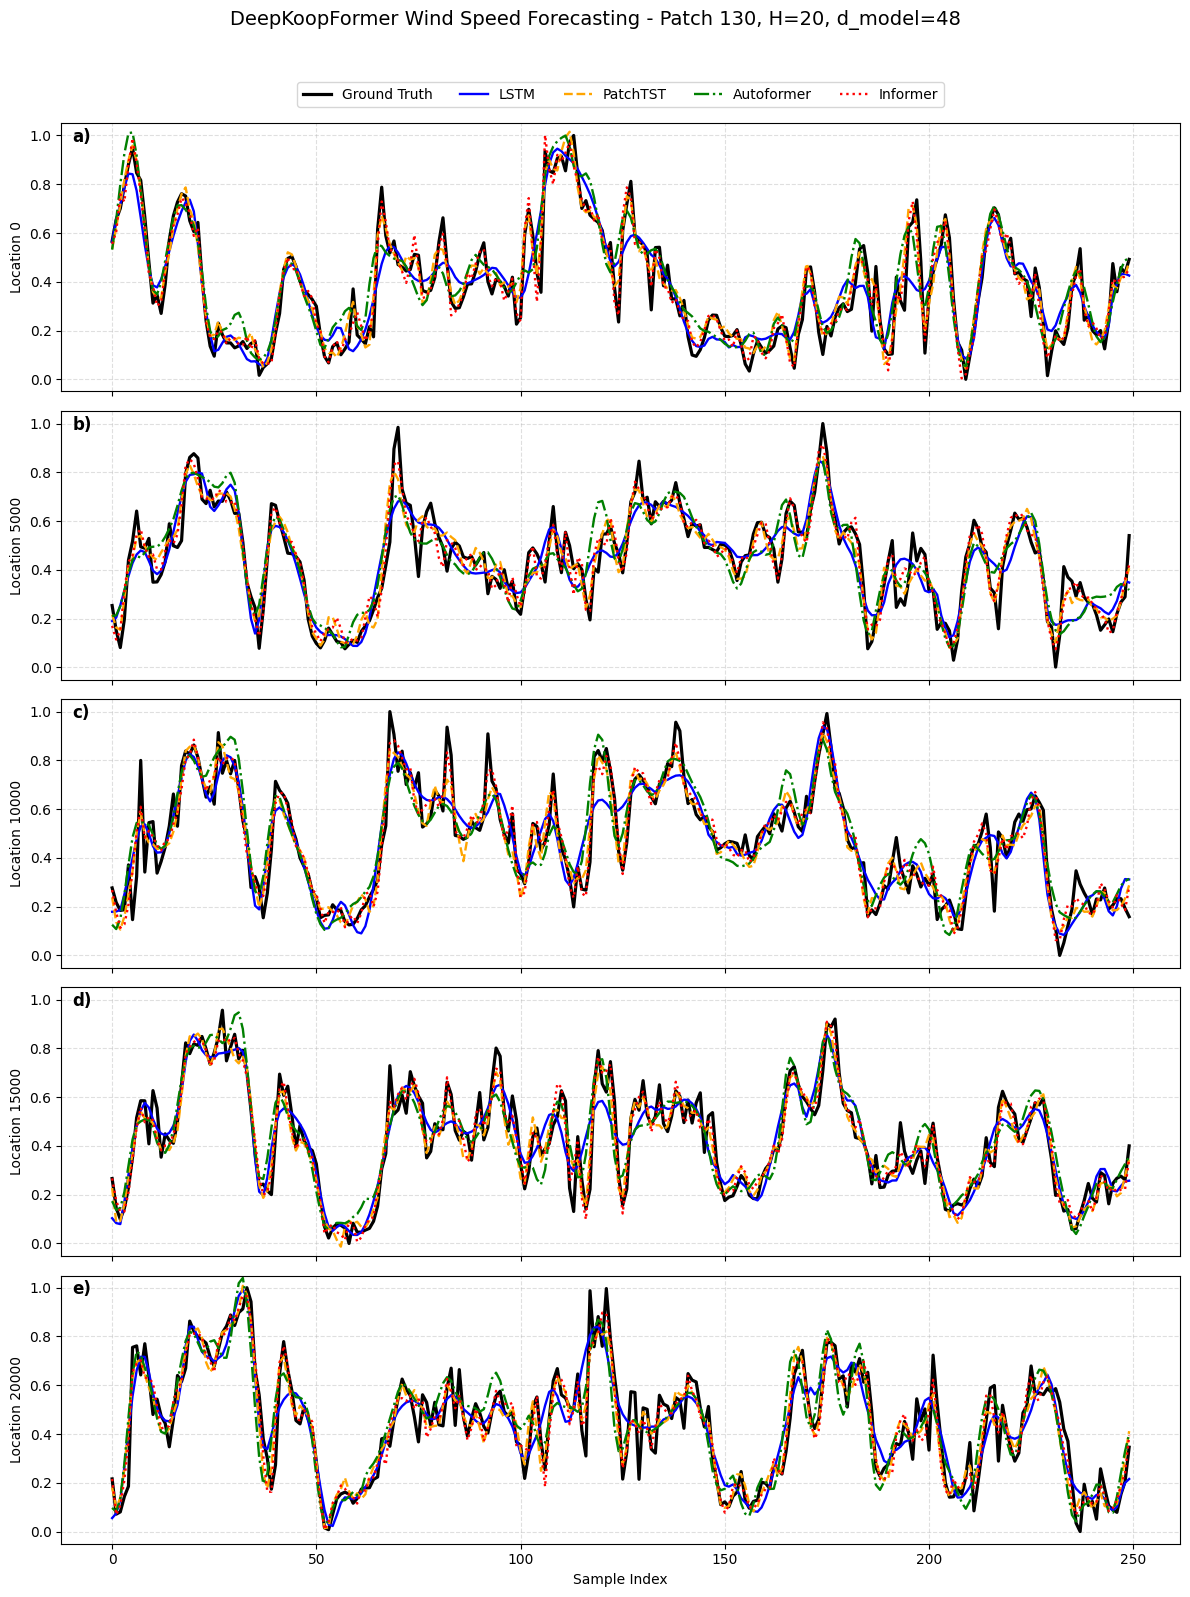

In [4]:

fig4_patch = 130
fig4_horizon = 20

model_files = {
    "LSTM": "lstm",
    "PatchTST": "patchtst",
    "Autoformer": "autoformer",
    "Informer": "informer"
}

# 1. Load saved predictions
fig4_results = {}

for name, filename in model_files.items():
    path = results_dir / f"{filename}_p{fig4_patch}_h{fig4_horizon}.pt"
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    fig4_results[name] = checkpoint

    print(f"{name}: MSE={checkpoint['mse']:.6f}, MAE={checkpoint['mae']:.6f}")

# 2. Reshape outputs: (250, 100) -> (250, 5, 20)
N = fig4_results["LSTM"]["truth"].shape[0]
F = input_dim
H = fig4_horizon

ground_truth = fig4_results["LSTM"]["truth"].numpy().reshape(N, F, H)[:, :, 0]

predictions = {
    name: ckpt["pred"].numpy().reshape(N, F, H)[:, :, 0]
    for name, ckpt in fig4_results.items()
}

# 3. Match Figure 4 line styles
styles = {
    "LSTM":       {"color": "blue",   "linestyle": "-"},
    "PatchTST":   {"color": "orange", "linestyle": "--"},
    "Autoformer": {"color": "green",  "linestyle": "-."},
    "Informer":   {"color": "red",    "linestyle": ":"}
}

fig, axes = plt.subplots(F, 1, figsize=(12, 16), sharex=True)

for site, ax in enumerate(axes):
    ax.plot(
        np.arange(N), ground_truth[:, site],
        color="black", linewidth=2.3,
        label="Ground Truth"
    )

    for name, pred in predictions.items():
        ax.plot(
            np.arange(N), pred[:, site],
            linewidth=1.7,
            label=name,
            **styles[name]
        )

    ax.set_ylabel(f"Location {dataset['location_indices'][site]}")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle="--", alpha=0.4)

    ax.text(
        0.01, 0.93, f"{chr(97 + site)})",
        transform=ax.transAxes,
        fontsize=12, fontweight="bold"
    )

axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.18))
axes[-1].set_xlabel("Sample Index")

fig.suptitle(
    "DeepKoopFormer Wind Speed Forecasting - Patch 130, H=20, d_model=48",
    fontsize=14,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.975])

plt.savefig(
    results_dir / "figure4_wind_speed_forecasting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
